# 02 — cGAN Experiments on Fashion-MNIST

Group **A Day in Ali** · CAK4KBB3 Project 1

This notebook runs and inspects the conditional GAN. All reusable logic lives in
`src/`; the notebook only calls it and shows the results:

1. Setup and data check
2. Model size
3. Training (resumes from the latest checkpoint if one exists)
4. Loss curves
5. Fixed-grid progress across epochs
6. Fresh samples per class from the trained generator
7. Evaluation (conditional accuracy, mode coverage)
8. Observations

## 1. Setup

In [1]:
import os
import sys
from pathlib import Path

# Run from the repo root so `src` imports and relative paths work.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import torch
from PIL import Image
from torchvision.utils import make_grid

from src.config import CHECKPOINTS_DIR, CLASS_NAMES, FIGURES_DIR, LATENT_DIM, LOGS_DIR, NUM_CLASSES, SAMPLES_DIR, SEED
from src.data import get_dataloader
from src.models import Discriminator, Generator, count_parameters
from src.train import train
from src.utils import get_device, load_checkpoint, set_seed

%matplotlib inline
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print("Repo root:", ROOT)
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())

Repo root: /home/mclr/Documents/Projects/Proyek1-CGAN-ADayInAli
torch 2.14.1+cu130 | CUDA available: True


### Experiment settings

Change these before running. `EPOCHS` is the last epoch to reach: with `RESUME = True`
an existing `outputs/checkpoints/ckpt.pt` is continued instead of starting over, so
re-running the notebook after training finishes does not retrain.

One epoch at batch size 128 takes about 80 seconds on a laptop CPU (≈40 minutes for 30).
Set `MAX_BATCHES` to a small number (e.g. `20`) for a quick smoke run.

In [2]:
EPOCHS = 30
BATCH_SIZE = 128
LR = 2e-4
SAMPLE_EVERY = 5
RESUME = True
MAX_BATCHES = None  # e.g. 20 for a quick smoke run
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

set_seed(SEED)
device = get_device(DEVICE)
print("Device:", device)

Device: cuda


### Data check

One batch of real images, rescaled from `[-1, 1]` back to `[0, 1]` for display.

Batch: (128, 1, 28, 28) | range: -1.0 to 1.0
Labels in batch: ['Ankle boot', 'Bag', 'Coat', 'Dress', 'Pullover', 'Sandal', 'Shirt', 'Sneaker', 'T-shirt/top', 'Trouser']


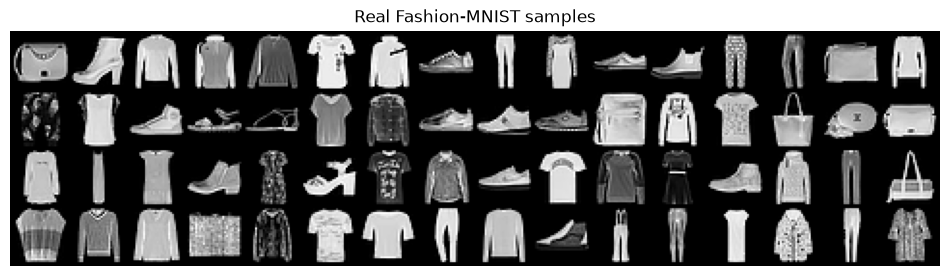

In [3]:
loader = get_dataloader(batch_size=BATCH_SIZE, seed=SEED)
images, labels = next(iter(loader))
print("Batch:", tuple(images.shape), "| range:", round(images.min().item(), 3), "to", round(images.max().item(), 3))
print("Labels in batch:", sorted({CLASS_NAMES[i] for i in labels.tolist()}))

grid = make_grid(images[:64], nrow=16, normalize=True, value_range=(-1, 1))
plt.figure(figsize=(12, 3.5))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("Real Fashion-MNIST samples")
plt.savefig(FIGURES_DIR / "real_samples.png", dpi=120, bbox_inches="tight")
plt.show()

## 2. Model size

In [4]:
g_params = count_parameters(Generator())
d_params = count_parameters(Discriminator())
print(f"Generator:     {g_params:>9,}")
print(f"Discriminator: {d_params:>9,}")
print(f"Total:         {g_params + d_params:>9,}")

Generator:       741,249
Discriminator:   192,881
Total:           934,130


## 3. Training

Each batch runs one discriminator update and one generator update
(`BCEWithLogitsLoss`, real targets 0.9, fake targets 0.0). Checkpoints, sample grids,
`history.json`, and `loss_curves.png` are written under `outputs/`.

In [5]:
ckpt_path = CHECKPOINTS_DIR / "ckpt.pt"
resume_from = ckpt_path if RESUME and ckpt_path.exists() else None
print("Resuming from:" if resume_from else "Starting fresh.", resume_from or "")

history = train(
    loader,
    epochs=EPOCHS,
    lr=LR,
    device=device,
    sample_every=SAMPLE_EVERY,
    resume=resume_from,
    seed=SEED,
    max_batches=MAX_BATCHES,
    progress=False,  # one summary line per epoch keeps the notebook small
)
print("Epochs recorded:", len(history["loss_d"]))

Resuming from: /home/mclr/Documents/Projects/Proyek1-CGAN-ADayInAli/outputs/checkpoints/ckpt.pt
Resumed from /home/mclr/Documents/Projects/Proyek1-CGAN-ADayInAli/outputs/checkpoints/ckpt.pt at epoch 30
Epochs recorded: 30


## 4. Loss curves

Healthy cGAN training usually shows both losses settling into a band rather than one
going to zero. Warning signs: discriminator loss near 0 with accuracy near 1
(D wins, G stops learning), or `D(G(z))` stuck near 0.

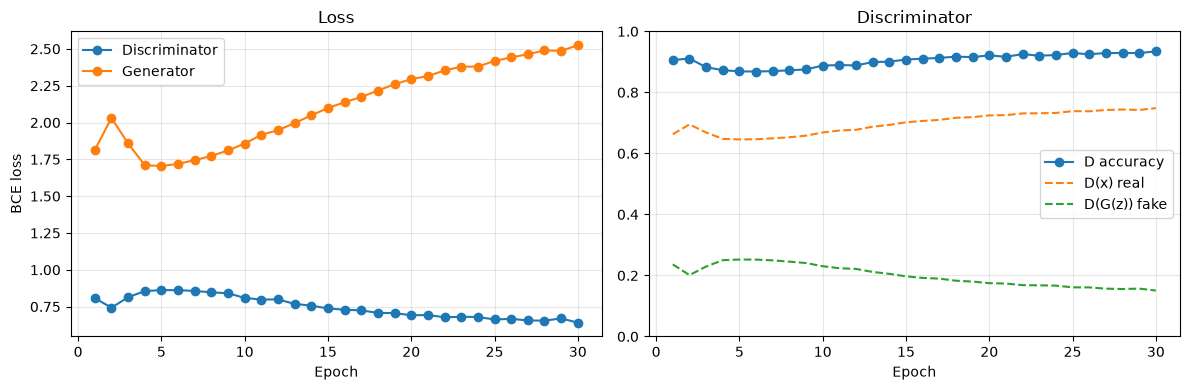

epoch   loss_d   loss_g  acc_d   D(x)  D(G(z))
    1   0.8084   1.8126  0.906  0.663    0.236
    2   0.7425   2.0308  0.911  0.695    0.201
    3   0.8137   1.8584  0.882  0.668    0.229
    4   0.8557   1.7103  0.873  0.648    0.250
    5   0.8619   1.7047  0.869  0.646    0.252
    6   0.8619   1.7189  0.868  0.646    0.252
    7   0.8564   1.7450  0.870  0.649    0.249
    8   0.8473   1.7727  0.872  0.653    0.245
    9   0.8408   1.8106  0.875  0.658    0.241
   10   0.8093   1.8571  0.888  0.668    0.230
   11   0.7977   1.9165  0.889  0.675    0.224
   12   0.7996   1.9484  0.888  0.677    0.221
   13   0.7682   1.9955  0.899  0.688    0.212
   14   0.7569   2.0489  0.901  0.693    0.205
   15   0.7376   2.0985  0.908  0.702    0.197
   16   0.7290   2.1377  0.910  0.706    0.192
   17   0.7245   2.1736  0.913  0.710    0.190
   18   0.7077   2.2170  0.917  0.717    0.183
   19   0.7061   2.2597  0.916  0.719    0.180
   20   0.6915   2.2945  0.921  0.725    0.175
   21   0.693

In [6]:
epochs_axis = range(1, len(history["loss_d"]) + 1)
fig, (ax_loss, ax_d) = plt.subplots(1, 2, figsize=(12, 4))
ax_loss.plot(epochs_axis, history["loss_d"], marker="o", label="Discriminator")
ax_loss.plot(epochs_axis, history["loss_g"], marker="o", label="Generator")
ax_loss.set(xlabel="Epoch", ylabel="BCE loss", title="Loss")
ax_loss.legend()
ax_d.plot(epochs_axis, history["acc_d"], marker="o", label="D accuracy")
ax_d.plot(epochs_axis, history["d_real"], linestyle="--", label="D(x) real")
ax_d.plot(epochs_axis, history["d_fake"], linestyle="--", label="D(G(z)) fake")
ax_d.set(xlabel="Epoch", ylim=(0, 1), title="Discriminator")
ax_d.legend()
for ax in (ax_loss, ax_d):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"{'epoch':>5} {'loss_d':>8} {'loss_g':>8} {'acc_d':>6} {'D(x)':>6} {'D(G(z))':>8}")
for i in epochs_axis:
    j = i - 1
    print(f"{i:>5} {history['loss_d'][j]:>8.4f} {history['loss_g'][j]:>8.4f} "
          f"{history['acc_d'][j]:>6.3f} {history['d_real'][j]:>6.3f} {history['d_fake'][j]:>8.3f}")

## 5. Fixed-grid progress

Every saved grid uses the same noise and labels, so changes between epochs come only
from training. Rows are classes in order (T-shirt/top at the top, Ankle boot at the bottom).

Saved grids: ['epoch_001.png', 'epoch_005.png', 'epoch_010.png', 'epoch_015.png', 'epoch_020.png', 'epoch_025.png', 'epoch_030.png']


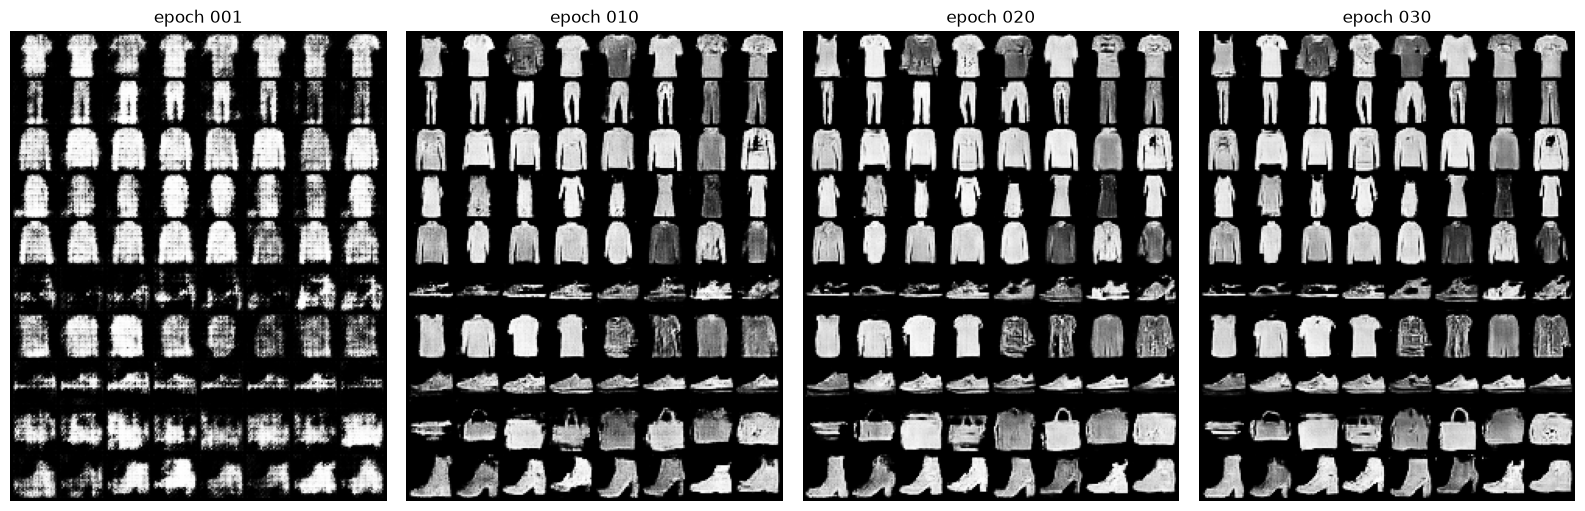

In [7]:
grid_files = sorted(SAMPLES_DIR.glob("epoch_*.png"))
print("Saved grids:", [p.name for p in grid_files])

if grid_files:
    # Show at most 4 grids, evenly spaced from first to last.
    n = len(grid_files)
    show = [grid_files[i] for i in sorted({round(k * (n - 1) / 3) for k in range(4)})]
    fig, axes = plt.subplots(1, len(show), figsize=(4 * len(show), 5), squeeze=False)
    for ax, path in zip(axes[0], show):
        ax.imshow(Image.open(path), cmap="gray")
        ax.set_title(path.stem.replace("_", " "))
        ax.axis("off")
    plt.tight_layout()
    fig.savefig(FIGURES_DIR / "sample_grid_progress.png", dpi=120, bbox_inches="tight")
    plt.show()

## 6. Fresh samples per class

New random noise (not the fixed grid) through the latest generator, in eval mode.
Each row should clearly show its labelled class and still vary within the row;
identical images across a row would suggest mode collapse.

Loaded generator from epoch 30


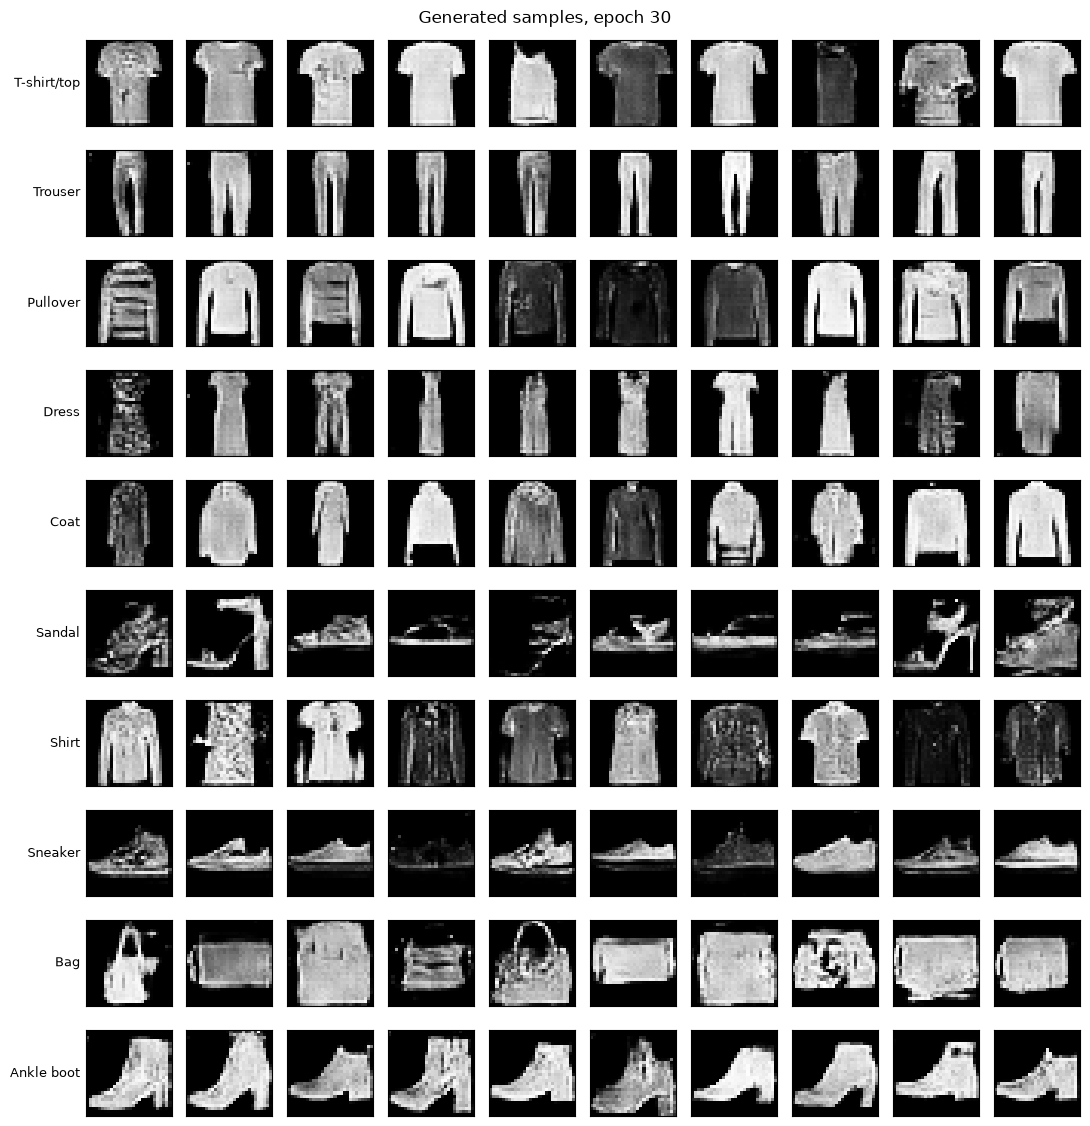

In [8]:
generator = Generator().to(device)
ckpt = load_checkpoint(ckpt_path, generator, device=device)
generator.eval()
print("Loaded generator from epoch", ckpt["epoch"])

per_class = 10
gen_rng = torch.Generator().manual_seed(SEED + 1)
z = torch.randn(NUM_CLASSES * per_class, LATENT_DIM, generator=gen_rng).to(device)
y = torch.arange(NUM_CLASSES, device=device).repeat_interleave(per_class)
with torch.no_grad():
    fakes = generator(z, y).cpu()

fig, axes = plt.subplots(NUM_CLASSES, per_class, figsize=(per_class * 1.1, NUM_CLASSES * 1.15))
for row in range(NUM_CLASSES):
    for col in range(per_class):
        ax = axes[row, col]
        ax.imshow(fakes[row * per_class + col, 0], cmap="gray", vmin=-1, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(CLASS_NAMES[row], rotation=0, ha="right", va="center", fontsize=9)
plt.suptitle(f"Generated samples, epoch {ckpt['epoch']}")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "fresh_samples_per_class.png", dpi=120, bbox_inches="tight")
plt.show()

## 7. Evaluation

`src/evaluate.py` trains a small CNN classifier on real Fashion-MNIST once (cached in
`outputs/checkpoints/classifier.pt`), generates 1,000 images per class, and reports:

- **Conditional accuracy:** share of generated images the classifier assigns to the requested
  label. Compare it with the classifier's own accuracy on real test images (the ceiling).
- **Prediction entropy:** spread of predicted classes over all generated images
  (1.0 = all ten classes equally represented).
- **Diversity ratio:** within-class spread of generated images in the classifier's feature
  space divided by the spread of real images of that class (≈1.0 = as varied as real data,
  near 0 = mode collapse).

In [9]:
from src.evaluate import evaluate, print_report

results = evaluate(CHECKPOINTS_DIR / "ckpt.pt", device=device)
print_report(results)


Checkpoint: /home/mclr/Documents/Projects/Proyek1-CGAN-ADayInAli/outputs/checkpoints/ckpt.pt (epoch 30)
Classifier accuracy on real test set: 0.9129
Conditional accuracy on generated:    0.9170
Prediction entropy (1.0 = balanced):  0.9986
Mean diversity ratio (1.0 = real):    0.9448

class         cond acc  real acc  diversity
T-shirt/top      0.852     0.864      0.892
Trouser          0.993     0.976      1.003
Pullover         0.777     0.819      0.923
Dress            0.951     0.932      0.944
Coat             0.891     0.907      0.976
Sandal           0.968     0.975      0.951
Shirt            0.774     0.730      0.941
Sneaker          0.973     0.976      0.919
Bag              0.997     0.983      0.954
Ankle boot       0.994     0.967      0.944


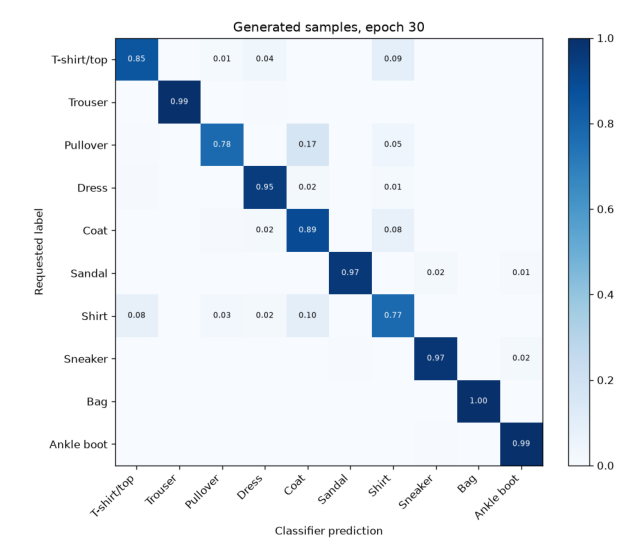

In [10]:
plt.figure(figsize=(8, 7))
plt.imshow(Image.open(LOGS_DIR / "confusion_ckpt.png"))
plt.axis("off")
plt.show()

### Metrics across saved checkpoints

epoch  cond acc  entropy  diversity
    1    0.7372   0.9279     0.6485
    5    0.8273   0.9786     0.8440
   10    0.9029   0.9979     0.8978
   15    0.9067   0.9987     0.9116
   20    0.9125   0.9987     0.9395
   25    0.9085   0.9982     0.9404
   30    0.9170   0.9986     0.9448


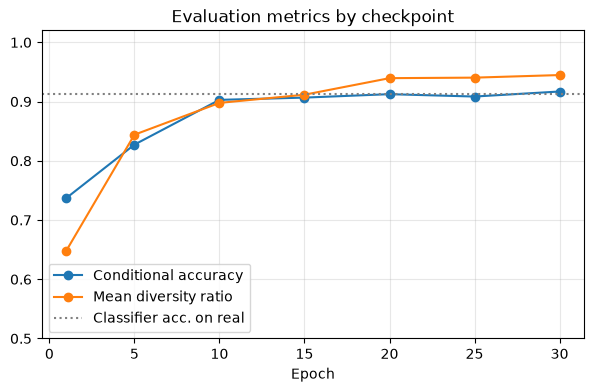

In [11]:
rows = []
for path in sorted(CHECKPOINTS_DIR.glob("ckpt_epoch_*.pt")):
    r = evaluate(path, per_class=1000, device=device)
    rows.append((r["epoch"], r["conditional_accuracy"], r["prediction_entropy"], r["mean_diversity_ratio"]))

print(f"{'epoch':>5} {'cond acc':>9} {'entropy':>8} {'diversity':>10}")
for e, acc, ent, div in rows:
    print(f"{e:>5} {acc:>9.4f} {ent:>8.4f} {div:>10.4f}")

ep = [r[0] for r in rows]
plt.figure(figsize=(7, 4))
plt.plot(ep, [r[1] for r in rows], marker="o", label="Conditional accuracy")
plt.plot(ep, [r[3] for r in rows], marker="o", label="Mean diversity ratio")
plt.axhline(results["classifier_test_accuracy"], color="gray", linestyle=":", label="Classifier acc. on real")
plt.xlabel("Epoch"); plt.ylim(0.5, 1.02); plt.grid(alpha=0.3); plt.legend()
plt.title("Evaluation metrics by checkpoint")
plt.savefig(FIGURES_DIR / "evaluation_metrics.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. Observations

Baseline run: 30 epochs, batch size 128, lr 2e-4, CPU (~80 s/epoch, ~40 min total).
These notes feed the *Optimasi* section of `logs/LOG_INTERAKSI_LLM.md` and the final report.

- **Training stability:** no divergence or collapse. After a short dip (epochs 3–6) the
  discriminator slowly gains ground: D accuracy rises from 0.86 to 0.93, `D(G(z))` falls
  from 0.26 to 0.15, and generator loss climbs from 1.68 to 2.51. Visual quality still
  improves up to epoch 30, but the gain from epoch 20 to 30 is small, so training much
  longer with this setup is unlikely to help.
- **Conditional accuracy:** 0.912 on 10,000 generated images, essentially equal to the
  classifier's 0.913 on real test images, so the generator follows the requested label
  about as reliably as real data allows. Most of the gain happens by epoch 10 (0.775 at
  epoch 1, 0.901 at epoch 10, 0.912 at epoch 30).
- **Class quality:** Trouser, Ankle boot, Bag, Sandal, and Sneaker reach 0.96–0.99.
  The weakest are Pullover (0.74; 17% classified as Coat) and Shirt (0.77; spread across
  T-shirt, Coat, and Pullover). These are the same classes the classifier confuses on real
  data, so part of the error is dataset overlap rather than the generator.
- **Diversity / mode collapse:** none. Prediction entropy is 0.998 (all classes equally
  represented) and the mean diversity ratio is 0.95 (lowest: T-shirt/top 0.91), close to
  real-data variety. Rows in the sample grid also vary visibly in shade, pattern, and shape.
- **Next experiment (max two variants):** because D slowly overpowers G, try
  (1) removing BatchNorm from the discriminator's first conv layer, or
  (2) a lower discriminator learning rate (e.g. 1e-4). Compare both against this baseline
  with `src/evaluate.py` (conditional accuracy 0.912, diversity ratio 0.95).